# Example training script for your model

This week I will provide the training script in the form of a jupyter notebook for your model but in other weeks you may be expected to write this yourself or just use a plain python script. Again, I cannot stop you from using AI but I will consider anything you submit as fair game to ask questions on so make you understand what you or your assistant have written.

In [95]:
# DO NOT REMOVE THESE
# These two lines make sure any changes you make in scaffold.py
# are automatically reloaded each time you run a cell in this notebook.
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [96]:
import pandas as pd
import numpy as np

# * imports everything from scaffold.py
from scaffold import *
# Install sklearn as - scikit-learn
from sklearn.model_selection import train_test_split


In [97]:
data = pd.read_csv('data_train.csv')
# Split the data into training and test sets
# The reason we do this is so that we can evaluated the performance 
# on unseen data. If we just evaluated on the training data,
# we would not know if the model is overfitting or not. 
train_data, test_data = train_test_split(data, test_size=0.2, random_state=42)
train_data = train_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)
print(f"Train data shape: {train_data.shape}")
print(f"Test data shape: {test_data.shape}")

Train data shape: (8000, 8)
Test data shape: (2000, 8)


In [98]:
features = [col for col in data.columns if col != 'y']
print(f"Features: {features}")

Features: ['x_1', 'x_2', 'x_3', 'x_4', 'x_5', 'x_6', 'x_7']


In [240]:
# Your model may need to be initialised in a different way.
model = Regression(max_dim=6,stepsize=1, lmbda= 0.0001)

In [241]:
# Fit the parameters on the training data
model.fit(train_data[features], train_data['y'])
# You can adjust this to print the parameters in a different way if you want.
# This may not be the most informative.
print(f"Model parameters: {model.theta}")

Model parameters: [ 2.01297596e+01 -5.55106532e+06 -3.36624771e+06  4.14388184e+07
  4.20426931e+06 -3.44974153e+07  4.20627225e+06 -1.38828660e+07
 -4.97785400e+00  7.17580884e+00 -4.09466099e-01  1.59839407e+01
  7.16086928e-01 -2.96968339e+01  1.55461599e-02  3.85837844e-02
 -6.05384689e-02  2.33299526e-03 -1.68563659e-01 -4.02537015e-03
  3.88342980e-01  5.71759511e-04 -1.62819573e-04  2.78015182e-04
 -7.70011631e-06  9.95653318e-04  1.27394200e-05 -2.82396816e-03
  7.08544200e-06  3.55994165e-07 -6.61077802e-07  1.33247550e-08
 -3.12274322e-06 -2.11262969e-08  1.08219281e-05  3.05204266e-08
 -3.16339137e-10  6.38247959e-10 -9.30374453e-12  4.06016517e-09
  1.42914309e-11 -1.70597120e-08  1.20762031e-11]


In [242]:
# Create predictions for the training data
predictions_train = model.predict(train_data[features])

# Score those predictions on the training data
# We will just use MSE (mean squared error) as the metric for now.
mse_train = np.mean((predictions_train - train_data['y'])**2)
print(f"Training MSE: {mse_train}")

Training MSE: 51.49548632060706


In [243]:
# Create predictions for the test data.
predictions = model.predict(test_data[features])


# Score those predictions on the test data
# Again using the MSE as the metric for now.
mse_test = np.mean((predictions - test_data['y'])**2)
print(f"Test MSE: {mse_test}")

Test MSE: 49.51186510900543


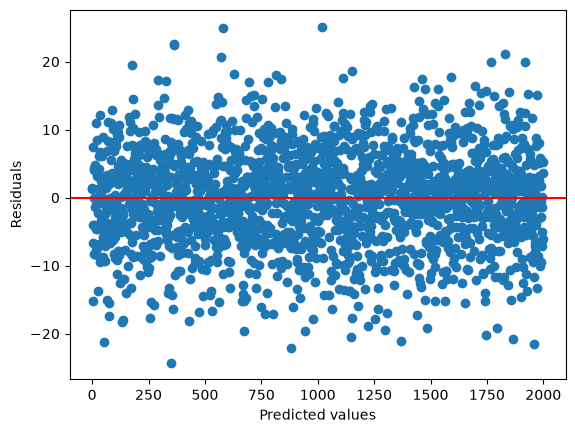

In [244]:
# You may want to plot the residuals to see if there are any patterns 
# your model is not capturing. This can be a good way to debug your model.
import matplotlib.pyplot as plt

residuals = predictions - test_data["y"].to_numpy()
plt.scatter(np.arange(len(predictions)), residuals)
plt.axhline(y=0, color="r")
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.show()



## Submitting to a hidden validation set
There is an online validation that runs in your browser. Here you can compare your result vs your coursemates and also vs 3 baselines I have uploaded previously.

To upload: Use only scaffold.py and make sure your model class is named Regression. 

Naming: I suggest not using your full name to upload here as it is a public website.

Good luck!